# Load data
For this subquestion the data of rijdendetreinen.nl is used
https://www.rijdendetreinen.nl/open-data/treinarchief#downloads 

The data of September is sseptember 2026 has been downloaded from the archive on the site. 



In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = r"data/services-2026-09.csv"

df = pd.read_csv(
    file_path,
    low_memory=False
)

#print rows to check whether data has been loaded correctly
print(f"Rows in dataset: {len(df):,}")

Rows in dataset: 1,863,470


# Select date and stations in corridor
For this analysis, only data from the big stations in the corridor is used: Deventer, Amersfoort and Apeldoorn. The other stations are ignored, since these stations represent bigger distances over the corridor. 

In [17]:
# Select disruption day

df = df[
    df["Service:Date"] == "2026-09-15"
].copy()

# Select stations on the corridor

corridor_stations = [
    "Amersfoort Centraal",
    "Apeldoorn",
    "Deventer"
]

df = df[
    df["Stop:Station name"].isin(corridor_stations)
].copy()

print(f"Rows after station filter: {len(df):,}")
print(f"Unique train services: {df['Service:RDT-ID'].nunique():,}")

Rows after station filter: 1,490
Unique train services: 1,001


# Select train types
Only train services likely to serve medium- and long-distance travellers were included. Local stopping services and replacement buses were excluded.

In [18]:
relevant_types = [
    "Intercity",
    "Intercity direct",
    "ICE",
    "Sneltrein",
    "GoVolta",
    "European Sleeper",
    "Nightjet"
]

df = df[
    df["Service:Type"].isin(relevant_types)
].copy()

print("Remaining train types:\n")
print(df["Service:Type"].value_counts())

print("\nUnique train services:")
print(df["Service:RDT-ID"].nunique())

Remaining train types:

Service:Type
Intercity           795
Intercity direct     70
ICE                  42
Sneltrein             8
Name: count, dtype: int64

Unique train services:
523


#  Create data-set with 1 data-unit per trainservice

In [19]:
# Determine event time

df["event_time"] = pd.to_datetime(
    df["Stop:Departure time"],
    errors="coerce"
)

missing = df["event_time"].isna()

df.loc[missing, "event_time"] = pd.to_datetime(
    df.loc[missing, "Stop:Arrival time"],
    errors="coerce"
)

df["hour"] = df["event_time"].dt.hour

# Aggregate to services

services = (
    df.groupby("Service:RDT-ID")
      .agg(
          hour=("hour", "min"),
          fully_cancelled=("Service:Completely cancelled", "max"),
          partly_cancelled=("Service:Partly cancelled", "max")
      )
      .reset_index()
)

services = services.dropna(subset=["hour"])

services["hour"] = services["hour"].astype(int)

services["affected"] = (
    services["fully_cancelled"]
    | services["partly_cancelled"]
)

print(services.head())

   Service:RDT-ID  hour  fully_cancelled  partly_cancelled  affected
0        19190925     5            False              True      True
1        19190960     6            False              True      True
2        19190968     6            False              True      True
3        19190970     8            False              True      True
4        19190972     5            False              True      True


In [20]:
hours = pd.Index(range(24))

total = (
    services.groupby("hour")
            .size()
            .reindex(hours, fill_value=0)
)

affected = (
    services[services["affected"]]
    .groupby("hour")
    .size()
    .reindex(hours, fill_value=0)
)

normal = total - affected

affected_pct = (
    affected
    / total.replace(0, np.nan)
) * 100

summary = pd.DataFrame({
    "Total services": total,
    "Affected services": affected,
    "Operating services": normal,
    "Affected (%)": affected_pct.round(1)
})

summary

,Total services,Affected services,Operating services,Affected (%)
0,15,0,15,0.0
1,1,0,1,0.0
2,0,0,0,NaN
3,0,0,0,NaN
4,0,0,0,NaN
5,7,6,1,85.7
6,29,24,5,82.8
7,35,31,4,88.6
8,33,29,4,87.9
9,30,27,3,90.0


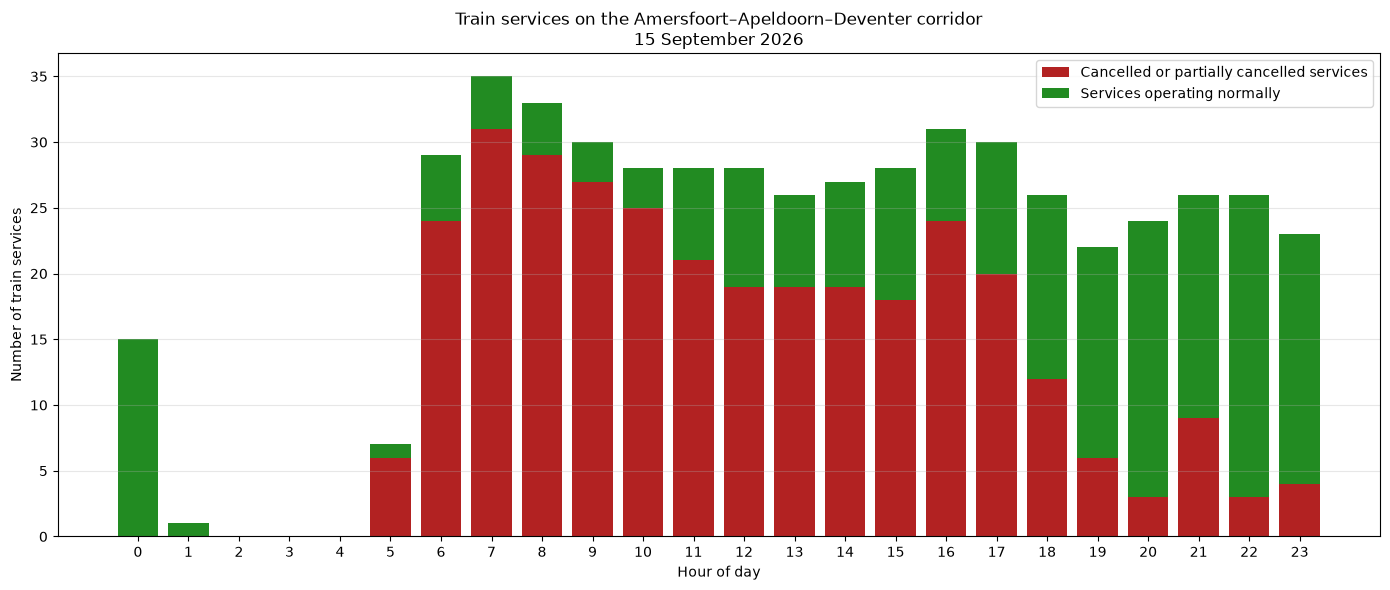

In [21]:
plt.figure(figsize=(14,6))

plt.bar(
    hours,
    affected,
    color="firebrick",
    label="Cancelled or partially cancelled services"
)

plt.bar(
    hours,
    normal,
    bottom=affected,
    color="forestgreen",
    label="Services operating normally"
)

plt.xlabel("Hour of day")
plt.ylabel("Number of train services")

plt.title(
    "Train services on the Amersfoort–Apeldoorn–Deventer corridor\n"
    "15 September 2026"
)

plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

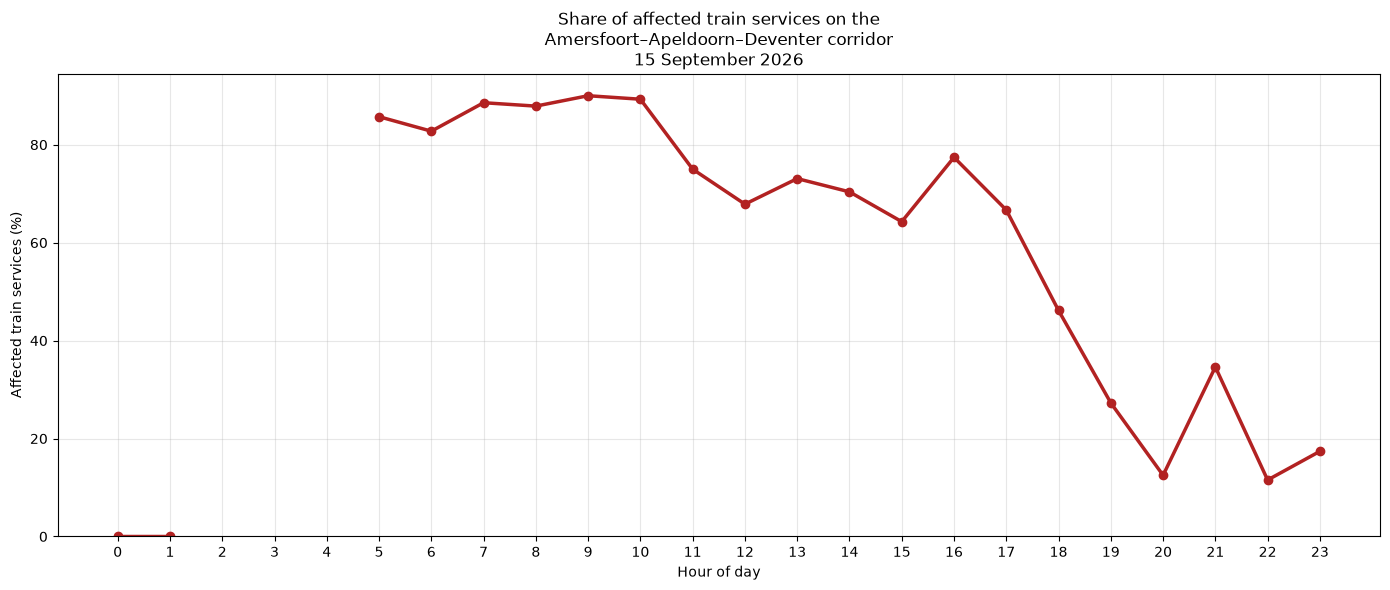

In [24]:
plt.figure(figsize=(14,6))

plt.plot(
    affected_pct.index,
    affected_pct.values,
    marker="o",
    linewidth=2.5,
    color="firebrick"
)

plt.xlabel("Hour of day")
plt.ylabel("Affected train services (%)")

plt.title(
    "Share of affected train services on the\n"
    "Amersfoort–Apeldoorn–Deventer corridor\n"
    "15 September 2026"
)

plt.xticks(range(24))
plt.ylim(bottom=0)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

,Average Tuesday disruptions,15 September disruptions
hour,,
5,6.5,31
6,3.8,29
7,5.5,27
8,7.2,25
9,6.3,21
10,6.8,19
11,4.8,19
12,2.2,19
13,3.5,18


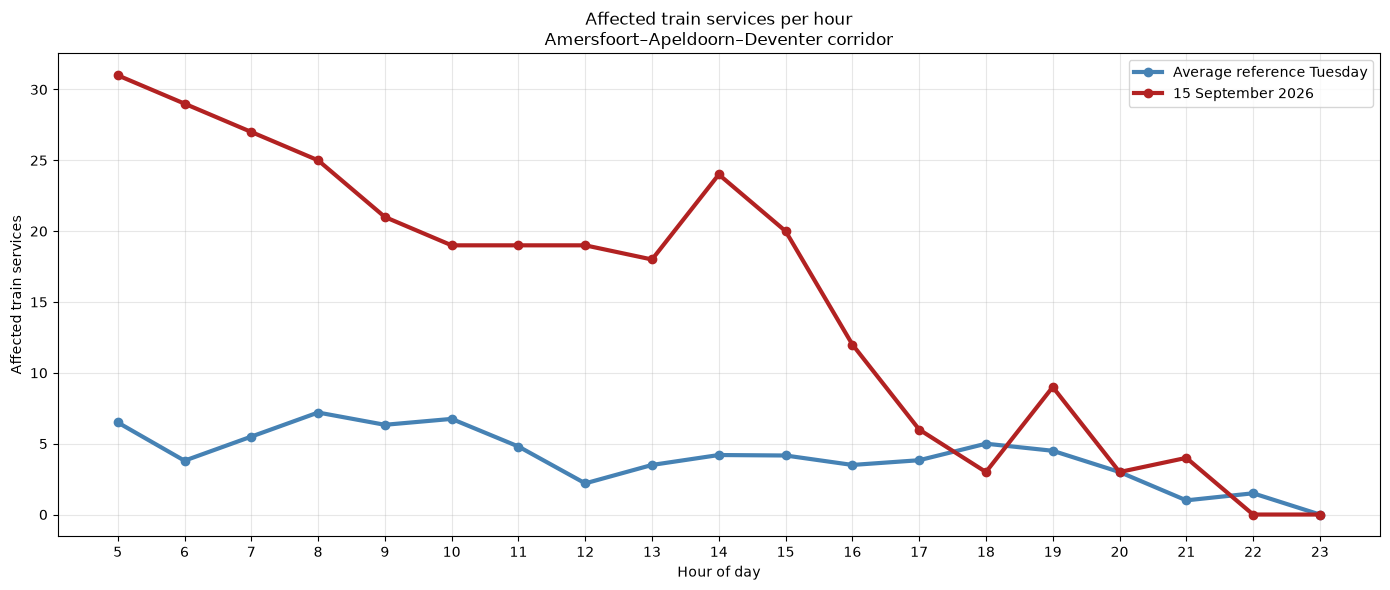

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# LOAD DATA

files = [
    r"data/services-2026-08.csv",
    r"data/services-2026-09.csv",
    r"data/services-2026-10.csv"
]

df = pd.concat(
    [pd.read_csv(f, low_memory=False) for f in files],
    ignore_index=True
)

# FILTER STATIONS

corridor_stations = [
    "Amersfoort Centraal",
    "Apeldoorn",
    "Deventer"
]

df = df[
    df["Stop:Station name"].isin(corridor_stations)
].copy()


# FILTER TRAIN TYPES

relevant_types = [
    "Intercity",
    "Intercity direct",
    "ICE",
    "Sneltrein",
    "GoVolta",
    "European Sleeper",
    "Nightjet"
]

df = df[
    df["Service:Type"].isin(relevant_types)
].copy()

# CREATE TIMESTAMP - On October 25, 2026 The timezone changed because of winter and summertime
df["event_time"] = pd.to_datetime(
    df["Stop:Departure time"],
    errors="coerce",
    utc=True
)

missing = df["event_time"].isna()

df.loc[missing, "event_time"] = pd.to_datetime(
    df.loc[missing, "Stop:Arrival time"],
    errors="coerce",
    utc=True
)

df["hour"] = df["event_time"].dt.hour


# AGGREGATE TO SERVICEs

services = (
    df.groupby(
        ["Service:Date", "Service:RDT-ID"]
    )
    .agg(
        hour=("hour", "min"),
        fully_cancelled=("Service:Completely cancelled", "max"),
        partly_cancelled=("Service:Partly cancelled", "max")
    )
    .reset_index()
)

services = services.dropna(subset=["hour"])

services["hour"] = services["hour"].astype(int)

services["affected"] = (
    services["fully_cancelled"]
    | services["partly_cancelled"]
)


# SELECT DATES

baseline_dates = [
    "2026-08-25",
    "2026-09-01",
    "2026-09-08",
    "2026-09-22",
    "2026-09-29",
    "2026-10-06"
]

disruption_date = "2026-09-15"


# BASELINE DISRUPTIONS

baseline = services[
    services["Service:Date"].isin(baseline_dates)
]

baseline_hourly = (
    baseline[baseline["affected"]]
    .groupby(["Service:Date", "hour"])
    .size()
    .reset_index(name="affected")
)

expected = (
    baseline_hourly
    .groupby("hour")["affected"]
    .mean()
)


# DISRUPTION DAY

observed = (
    services[
        (services["Service:Date"] == disruption_date)
        & (services["affected"])
    ]
    .groupby("hour")
    .size()
)

hours = range(5, 24)

expected = expected.reindex(hours, fill_value=0)
observed = observed.reindex(hours, fill_value=0)

# Table

comparison = pd.DataFrame({
    "Average Tuesday disruptions": expected.round(1),
    "15 September disruptions": observed
})

display(comparison)


# PLOT
plt.figure(figsize=(14,6))

plt.plot(
    expected.index,
    expected.values,
    color="steelblue",
    linewidth=3,
    marker="o",
    label="Average reference Tuesday"
)

plt.plot(
    observed.index,
    observed.values,
    color="firebrick",
    linewidth=3,
    marker="o",
    label="15 September 2026"
)

plt.xlabel("Hour of day")
plt.ylabel("Affected train services")

plt.title(
    "Affected train services per hour\n"
    "Amersfoort–Apeldoorn–Deventer corridor"
)

plt.xticks(range(5,24))
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()